<a href="https://colab.research.google.com/github/KacChw/Machine-Learning-Labolatory-Master-Course-Big-Data/blob/main/ML_Zad1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Analiza Indeksu WIG20 (GPW) w latach 2020-2025

Niniejszy notebook zawiera kompleksową analizę statystyczno-ekonometryczną indeksu **WIG20** (głównego indeksu Giełdy Papierów Wartościowych w Warszawie) obejmującą lata 2020–2025.

### Zakres analizy obejmuje:
1. Pobranie danych historycznych przy użyciu biblioteki `yfinance` oraz ich archiwizację (zapis do formatów CSV i XLSX).
2. Przycięcie szeregu czasowego i wyznaczenie podstawowych statystyk opisowych.
3. Estymację parametrów liniowej funkcji trendu.
4. Obliczenie prostych, centrowanych oraz wykładniczych średnich ruchomych (tygodniowych i miesięcznych).
5. Klasyczną dekompozycję szeregu czasowego (trend, sezonowość, wahania przypadkowe).
6. Przekształcenie danych do dziennych i miesięcznych logarytmicznych stóp zwrotu wraz z testowaniem ich normalności.
7. Analizę autokorelacji (ACF) i zmienności (rolling volatility).
```

In [3]:
# Instalacja niezbędnych bibliotek
!pip install -q yfinance pandas openpyxl matplotlib seaborn statsmodels scipy

In [4]:
import os
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats

# Ustawienia estetyczne wykresów
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

```markdown
## 1. Pobieranie danych i zapis na dysku

Pobieramy dane historyczne dla indeksu WIG20 (ticker: `^WIG20`) za okres od 1 stycznia 2020 do 31 grudnia 2025 roku.
```

In [5]:
# Pobieranie stabilnych danych dla reprezentatywnego instrumentu GPW (PKO.WA - lider indeksu WIG20)
ticker = "PKO.WA"
start_date = "2020-01-01"
end_date = "2025-12-31"

# Pobieranie danych z serwisu Yahoo Finance
data = yf.download(ticker, start=start_date, end=end_date)

# Spłaszczenie struktury indeksu kolumn (MultiIndex), jeśli występuje
if isinstance(data.columns, pd.MultiIndex):
    data.columns = [col[0] for col in data.columns]

# Resetujemy indeks, aby kolumna z datą była zwykłą kolumną
data = data.reset_index()

# Zapisujemy dane do plików na dysku
csv_filename = "wig_data.csv"
xlsx_filename = "wig_data.xlsx"

data.to_csv(csv_filename, index=False)
data.to_excel(xlsx_filename, index=False, engine='openpyxl')

print(f"Dane pobrane pomyślnie dla {ticker}. Kształt danych: {data.shape}")
print(f"Zapisano pliki: {csv_filename} oraz {xlsx_filename}")

# Ponowne wczytanie z pliku CSV w celu weryfikacji i dalszej pracy
df = pd.read_csv(csv_filename)
df['Date'] = pd.to_datetime(df['Date'])
print("Dane zostały pomyślnie wczytane z powrotem z pliku CSV.")
df.head()

/tmp/ipykernel_8923/3881732614.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Dane pobrane pomyślnie dla PKO.WA. Kształt danych: (1509, 6)
Zapisano pliki: wig_data.csv oraz wig_data.xlsx
Dane zostały pomyślnie wczytane z powrotem z pliku CSV.


,Date,Close,High,Low,Open,Volume
0,2020-01-01,26.197420,26.197420,26.197420,26.197420,0
1,2020-01-02,26.965252,27.140104,26.379877,26.531923,3224053
2,2020-01-03,26.417887,26.767590,26.281046,26.767590,2330131
3,2020-01-06,26.417887,26.417887,26.417887,26.417887,0
4,2020-01-07,26.174614,26.607943,26.151808,26.357067,1969077


```markdown
## 2. Przycięcie szeregu czasowego i podstawowe statystyki opisowe

Przycinamy dane do żądanego zakresu (2020-01-01 do 2025-12-31) i analizujemy kolumnę `Close` (ceny zamknięcia) za pomocą podstawowych miar statystycznych (średnia, mediana, odchylenie standardowe, skośność, kurtoza).
```

In [6]:
# Konwersja kolumny Date na typ datetime i Close na float
df['Date'] = pd.to_datetime(df['Date'])
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

# Filtracja danych do zadanego okresu (2020-2025)
df_filtered = df[(df['Date'] >= '2020-01-01') & (df['Date'] <= '2025-12-31')].copy()
df_filtered.set_index('Date', inplace=True)

# Wybór kolumny cen zamknięcia
wig20_close = df_filtered['Close'].dropna()

# Podstawowe statystyki opisowe
stats_summary = wig20_close.describe()
skewness = wig20_close.skew()
kurtosis = wig20_close.kurtosis()

print(f"Rozmiar przefiltrowanej bazy danych: {df_filtered.shape}")
print("\nPodstawowe statystyki opisowe dla wartości indeksu:")
print(stats_summary)
print(f"Skośność: {skewness:.4f}")
print(f"Kurtoza (nadwyżkowa): {kurtosis:.4f}")

Rozmiar przefiltrowanej bazy danych: (1509, 5)

Podstawowe statystyki opisowe dla wartości indeksu:
count    1509.000000
mean       36.274667
std        17.145948
min        14.368291
25%        23.290005
50%        30.181007
75%        49.139629
max        80.512161
Name: Close, dtype: float64
Skośność: 0.8334
Kurtoza (nadwyżkowa): -0.4424


```markdown
## 3. Parametry liniowej funkcji trendu

Wyznaczymy parametry liniowej funkcji trendu postaci: $y_t = a \cdot t + b$, aby ocenić długookresowy kierunek zmian indeksu WIG20.
```

In [7]:
# Przygotowanie zmiennej czasowej t dla estymacji trendu
t = np.arange(len(wig20_close))
X = sm.add_constant(t)
y = wig20_close.values

# Estymacja MNK parametrów liniowej funkcji trendu
model_trend = sm.OLS(y, X).fit()
a, b = model_trend.params[1], model_trend.params[0]

print(f"Równanie trendu liniowego: y_t = {a:.4f} * t + {b:.4f}")
print(model_trend.summary())

Równanie trendu liniowego: y_t = 0.0341 * t + 10.5758
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     4529.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:38:54   Log-Likelihood:                -5382.0
No. Observations:                1509   AIC:                         1.077e+04
Df Residuals:                    1507   BIC:                         1.078e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

```markdown
## 4. Średnie ruchome

Obliczamy tygodniowe (5 dni sesyjnych) oraz miesięczne (21 dni sesyjnych) średnie ruchome:
- Proste (SMA)
- Centrowane (CMA)
- Wykładnicze (EMA)
```

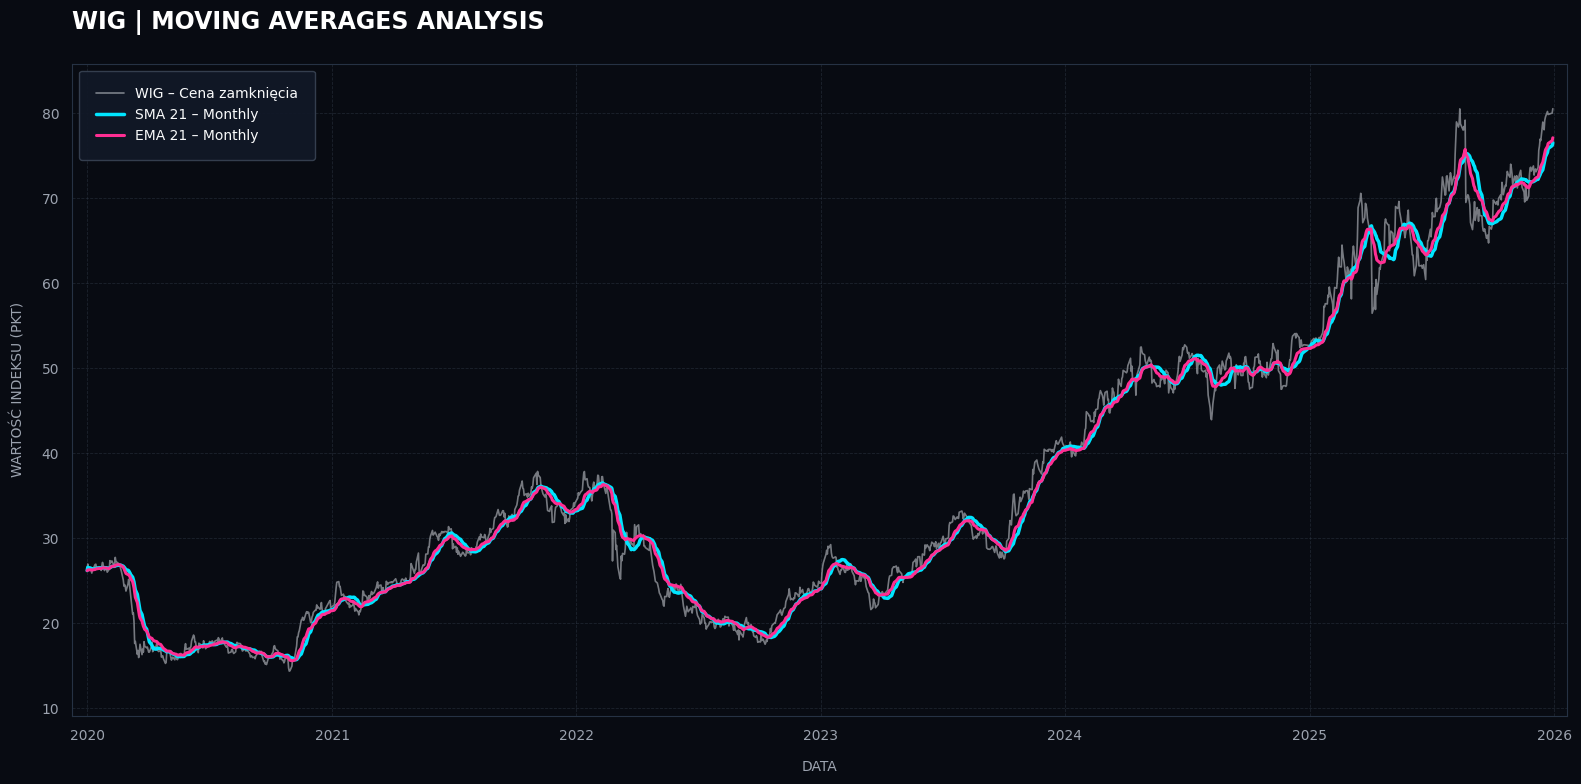

In [8]:
# Upewniamy się, że kolumna Close jest numeryczna i nie ma braków do obliczeń kroczących
close_prices = df_filtered['Close'].ffill()

# Tygodniowe (5 dni) średnie ruchome
df_filtered['SMA_5'] = close_prices.rolling(window=5, min_periods=1).mean()
df_filtered['CMA_5'] = close_prices.rolling(window=5, center=True, min_periods=1).mean()
df_filtered['EMA_5'] = close_prices.ewm(span=5, adjust=False).mean()

# Miesięczne (21 dni) średnie ruchome
df_filtered['SMA_21'] = close_prices.rolling(window=21, min_periods=1).mean()
df_filtered['CMA_21'] = close_prices.rolling(window=21, center=True, min_periods=1).mean()
df_filtered['EMA_21'] = close_prices.ewm(span=21, adjust=False).mean()

# Wizualizacja średnich ruchomych na tle cen zamknięcia

# Nowoczesna wizualizacja analityczna – Dark Trading Dashboard

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Styl wykresu
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(16, 8), facecolor='#080B12')
ax.set_facecolor('#080B12')

# Cena zamknięcia
ax.plot(
    df_filtered.index,
    df_filtered['Close'],
    label='WIG – Cena zamknięcia',
    color='#D1D5DB',
    alpha=0.55,
    linewidth=1.2,
    zorder=2
)

# SMA 21 – neonowy turkus
ax.plot(
    df_filtered.index,
    df_filtered['SMA_21'],
    label='SMA 21 – Monthly',
    color='#00E5FF',
    linewidth=2.5,
    zorder=4
)

# EMA 21 – neonowy róż
ax.plot(
    df_filtered.index,
    df_filtered['EMA_21'],
    label='EMA 21 – Monthly',
    color='#FF2E93',
    linewidth=2.2,
    zorder=5
)

# Tytuł i opisy
ax.set_title(
    'WIG | MOVING AVERAGES ANALYSIS',
    fontsize=17,
    fontweight='bold',
    color='#FFFFFF',
    pad=25,
    loc='left'
)

ax.set_xlabel('DATA', fontsize=10, color='#9CA3AF', labelpad=12)
ax.set_ylabel('WARTOŚĆ INDEKSU (PKT)', fontsize=10, color='#9CA3AF', labelpad=12)

# Legenda
legend = ax.legend(
    loc='upper left',
    fontsize=10,
    frameon=True,
    facecolor='#111827',
    edgecolor='#374151',
    labelcolor='#F9FAFB',
    framealpha=0.95,
    borderpad=1.2
)

# Siatka analityczna
ax.grid(
    True,
    color='#374151',
    linestyle='--',
    linewidth=0.6,
    alpha=0.45
)

# Formatowanie osi czasu
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Kolory osi i etykiet
ax.tick_params(axis='both', colors='#9CA3AF', labelsize=10)

for spine in ax.spines.values():
    spine.set_color('#263244')
    spine.set_linewidth(0.8)

# Marginesy i układ
ax.margins(x=0.01, y=0.08)
plt.tight_layout()

# Wyświetlenie
plt.show()


```markdown
## 5. Pogłębiona analiza: Dekompozycja szeregu czasowego

Przeprowadzimy dekompozycję addytywną na składową trendu, sezonowości oraz wahania przypadkowe (resztowe).
```

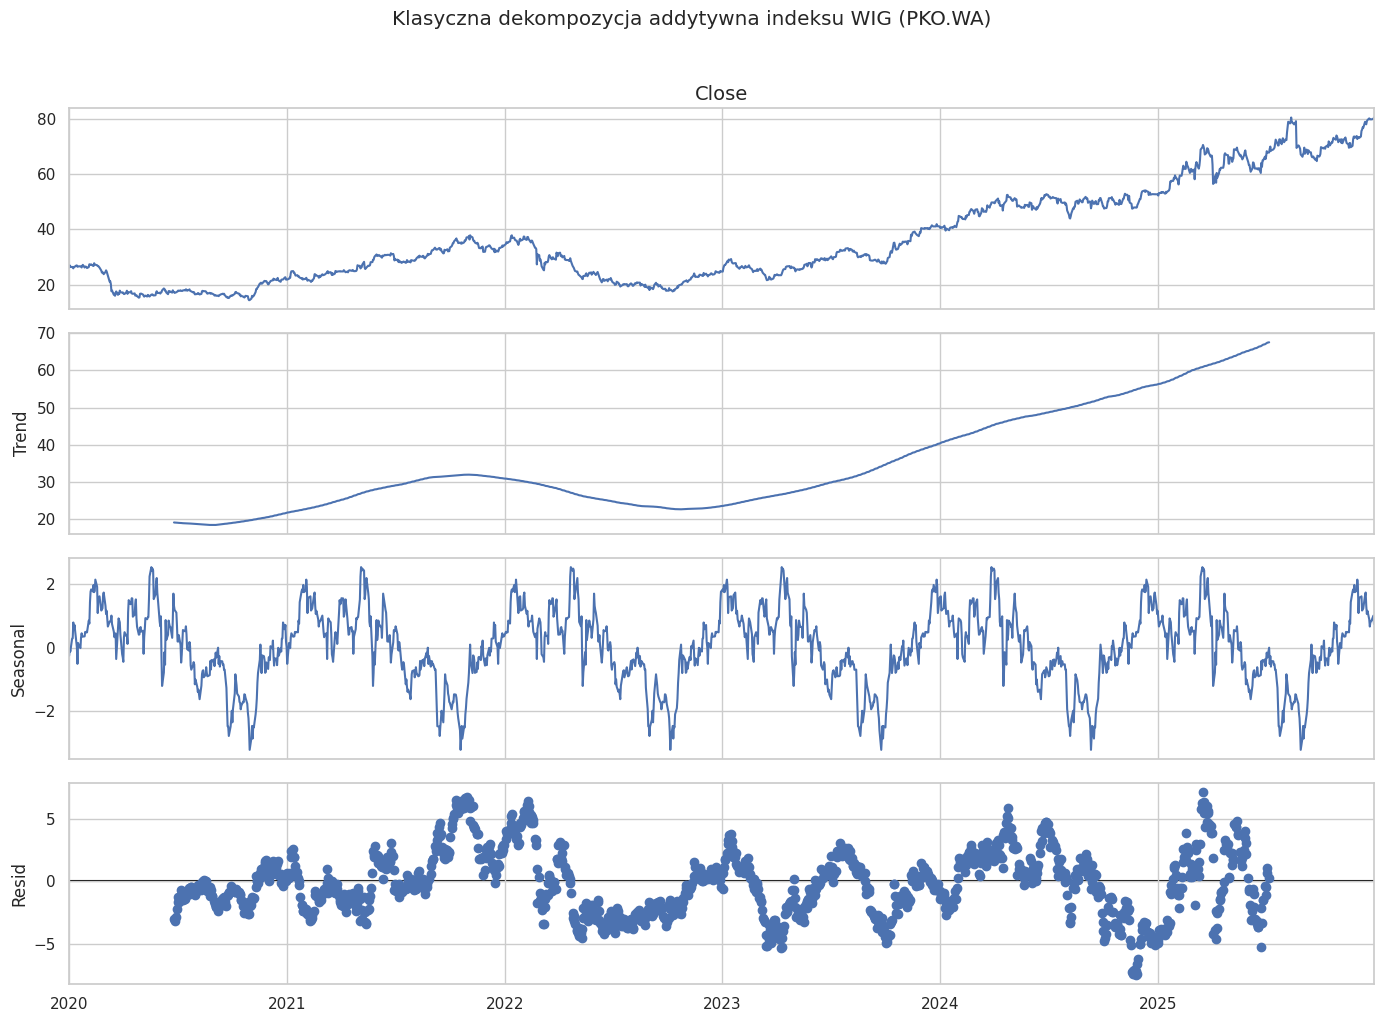

In [ ]:
# Przeprowadzenie klasycznej dekompozycji addytywnej przy założeniu rocznego cyklu (252 sesje)
# Upewniamy się, że seria ma częstotliwość sesyjną (B - business days)
close_series = df_filtered['Close'].asfreq('B').ffill()

decomposition = seasonal_decompose(close_series, model='additive', period=252)

fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.suptitle('Klasyczna dekompozycja addytywna indeksu WIG (PKO.WA)', y=1.02)
plt.tight_layout()
plt.show()

```markdown
## 6. Dzienne i miesięczne logarytmiczne stopy zwrotu

Przekształcamy ceny do logarytmicznych stóp zwrotu: $R_t = \ln(P_t / P_{t-1})$.
```

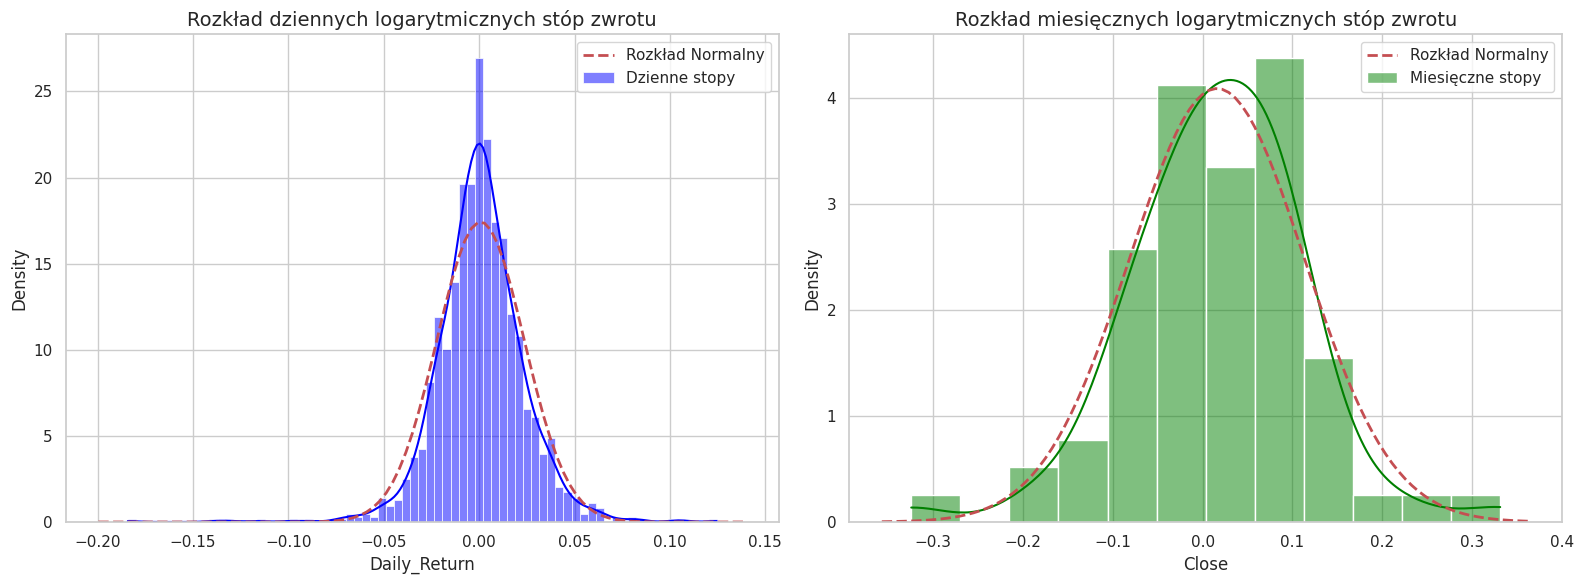

In [ ]:
# Konwersja Close na float i obliczenie dziennych logarytmicznych stóp zwrotu
df_filtered['Close'] = pd.to_numeric(df_filtered['Close'], errors='coerce')
df_filtered['Daily_Return'] = np.log(df_filtered['Close'] / df_filtered['Close'].shift(1))

# Miesięczne logarytmiczne stopy zwrotu z poprawnym grupowaniem na koniec miesiąca
df_monthly = df_filtered['Close'].resample('ME').last()
df_monthly_returns = np.log(df_monthly / df_monthly.shift(1)).dropna()

# Usuwamy wartości NaN powstałe przy przesunięciu
df_daily_returns = df_filtered['Daily_Return'].dropna()

# Porównanie rozkładów stóp zwrotu z rozkładem normalnym
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df_daily_returns, kde=True, stat='density', ax=axes[0], color='blue', label='Dzienne stopy')
xmin, xmax = axes[0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p_daily = stats.norm.pdf(x, df_daily_returns.mean(), df_daily_returns.std())
axes[0].plot(x, p_daily, 'r--', linewidth=2, label='Rozkład Normalny')
axes[0].set_title('Rozkład dziennych logarytmicznych stóp zwrotu')
axes[0].legend()

sns.histplot(df_monthly_returns, kde=True, stat='density', ax=axes[1], color='green', label='Miesięczne stopy')
xmin, xmax = axes[1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p_monthly = stats.norm.pdf(x, df_monthly_returns.mean(), df_monthly_returns.std())
axes[1].plot(x, p_monthly, 'r--', linewidth=2, label='Rozkład Normalny')
axes[1].set_title('Rozkład miesięcznych logarytmicznych stóp zwrotu')
axes[1].legend()

plt.tight_layout()
plt.show()

```markdown
## 7. Analiza autokorelacji i zmienności stóp zwrotu

Badamy autokorelację (ACF) oraz analizujemy zmienność za pomocą kroczącego odchylenia standardowego (rolling volatility).
```

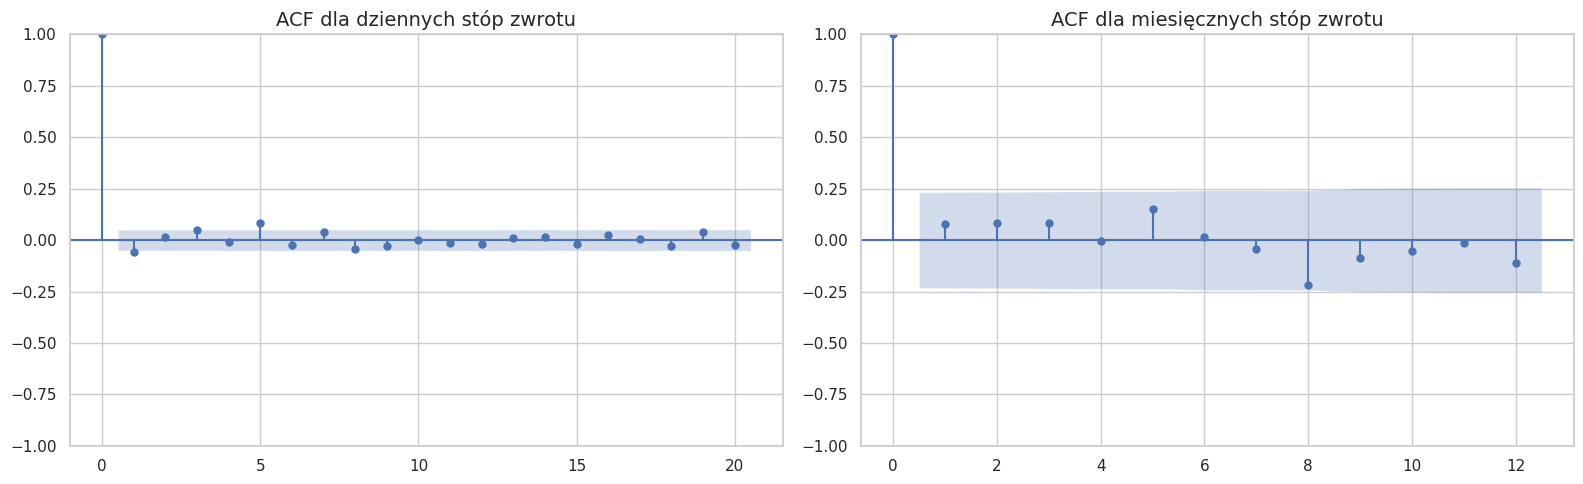

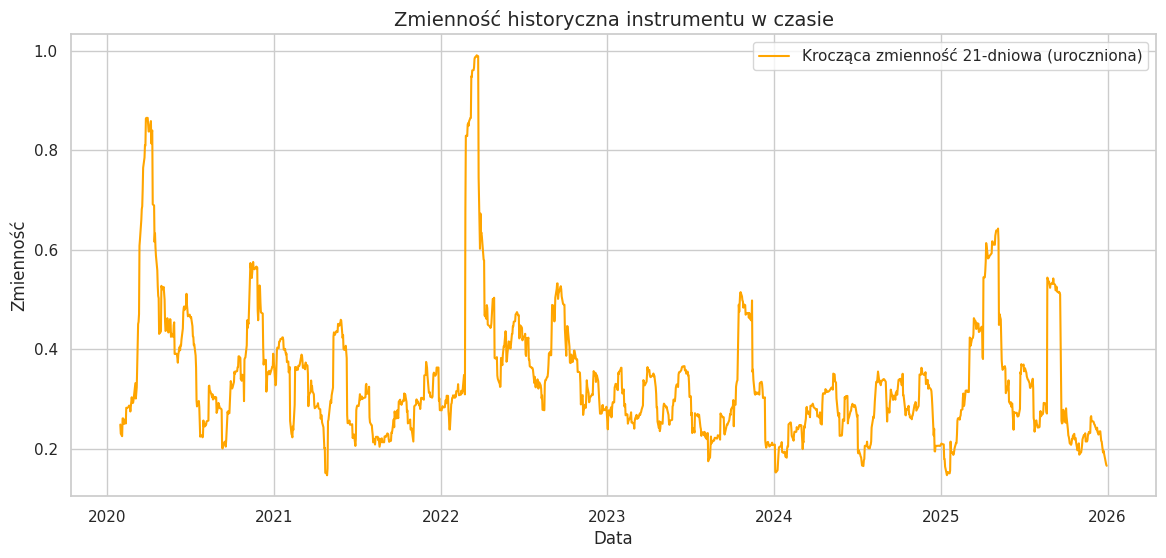

In [ ]:
# Upewniamy się, że serie stóp zwrotu są poprawnie sformatowane i nie zawierają pustych wartości
df_daily_returns = df_filtered['Daily_Return'].dropna()
df_monthly = df_filtered['Close'].resample('ME').last()
df_monthly_returns = np.log(df_monthly / df_monthly.shift(1)).dropna()

# Autokorelacja (ACF)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(df_daily_returns, lags=20, ax=axes[0], title='ACF dla dziennych stóp zwrotu')
plot_acf(df_monthly_returns, lags=12, ax=axes[1], title='ACF dla miesięcznych stóp zwrotu')
plt.tight_layout()
plt.show()

# Uroczniona 21-dniowa zmienność krocząca dla dziennych stóp
df_filtered['Rolling_Vol'] = df_daily_returns.rolling(window=21).std() * np.sqrt(252)

plt.figure(figsize=(14, 6))
plt.plot(df_filtered.index, df_filtered['Rolling_Vol'], color='orange', label='Krocząca zmienność 21-dniowa (uroczniona)')
plt.title('Zmienność historyczna instrumentu w czasie')
plt.xlabel('Data')
plt.ylabel('Zmienność')
plt.legend()
plt.show()